# Neural Networks - Regression

In this tutorial, we will create a regression model, that predicts the fuel efficiency in miles per gallon (MPG). This is a continuous value, in contrast with a classification model where a class is predicted.

## 0. Import python modules

We will use the Tensoflow/Keras framework for neural network machine learning.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from plot_loss import plot_loss # own function in plot_loss.py

## 1. Load the dataset

We read the dataset using pandas. The dataset is available from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/).

In [2]:
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'Origin']
dataset = pd.read_csv("../04-matplotlib/data/auto-mpg.csv", names=column_names, na_values='?', sep=' ', comment='\t', skipinitialspace=True)

In [3]:
dataset.tail()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
393,27.0,4,140.0,86.0,2790.0,15.6,82,1
394,44.0,4,97.0,52.0,2130.0,24.6,82,2
395,32.0,4,135.0,84.0,2295.0,11.6,82,1
396,28.0,4,120.0,79.0,2625.0,18.6,82,1
397,31.0,4,119.0,82.0,2720.0,19.4,82,1


## 2. Data cleaning and normalisation

The dataset contains a few unknown values which we will drop.

In [14]:
dataset.isna().sum()

MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [15]:
dataset = dataset.dropna()

We separate the input features `x` from the target values `y`.

In [16]:
x = dataset[["Cylinders","Displacement", "Horsepower", "Weight", "Acceleration", "Model Year"]]
y = dataset[['MPG']]

We now normalize the inputs using the `MinMaxScaler.` It is good practice always to do this so that all the features get the same scale and range (which is not the case in this dataset).

In [17]:
x.describe()

,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592
std,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737
min,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000
50%,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000
75%,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000
max,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [18]:
scaler = MinMaxScaler()
x_norm = scaler.fit_transform(x)

Next, we will split the data into a training and a test dataset.

In [19]:
x_train,x_test,y_train,y_test = train_test_split(x_norm,y,test_size=0.1) 

## 3. Define the model

The input layer has 6 nodes, corresponding to the number of input features. We choose 2 hidden layers with 64 nodes and a `relu` activation function (feel free to try other values/functions). The output layer has 1 node corresponding to the one MPG value to predict. For regression models, a `linear` activation function is often used in the output layer. We choose Adam as optimizer with a learning rate of `0.001`. The loss is the `MSE` loss which is often used for regression models. We also define a `mean_absolute_percentage_error` metric.

In [20]:
# input layer 6 nodes
inputs = Input(shape=(6,))
# 2 hidden layer
x = Dense(64, activation='relu')(inputs)
x = Dense(64, activation='relu')(x)
# output layer
outputs = Dense(1, activation='linear')(x)
# construct the model
model = Model(inputs, outputs, name='auto-mpg')
# print a summary
model.summary()
# compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=['mean_absolute_percentage_error']
)

Model: "auto-mpg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,673 (18.25 KB)

 Trainable params: 4,673 (18.25 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the model

We train the model for 100 epochs, with a batch size of 32 (feel free to try other values). We take 10% of the training dataset for validation data.

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 583.9727 - mean_absolute_percentage_error: 99.5997 - val_loss: 708.8017 - val_mean_absolute_percentage_error: 98.3165
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 562.4652 - mean_absolute_percentage_error: 96.8077 - val_loss: 683.0204 - val_mean_absolute_percentage_error: 95.6261
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 536.9421 - mean_absolute_percentage_error: 93.5092 - val_loss: 649.8422 - val_mean_absolute_percentage_error: 92.0929
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 503.1983 - mean_absolute_percentage_error: 89.1176 - val_loss: 605.8380 - val_mean_absolute_percentage_error: 87.1859
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 460.1109 - mean_absolute_percentage_error: 82.8996 - val_loss: 549.6843 - val_mean_absolute_percentage_error: 80.5255
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 405.7021 - mean_absolute_percentage_error: 74.1980 - va

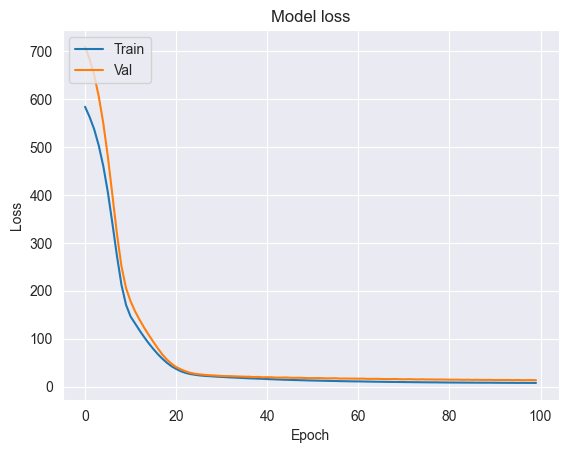

In [21]:
# train the model
history = model.fit(
    x_train, # training input
    y_train, # training targets
    epochs=100,
    batch_size=32,
    validation_split=0.1,
)
# plot loss function
plot_loss(history)

// todo explanation

## 📉 What the Loss Curve Shows
- Both training and validation loss decrease sharply in the first ~40 epochs.
- After that, loss stabilizes and both curves remain close together.
- No signs of overfitting: validation loss does not diverge from training loss.
- No signs of underfitting: the model clearly learns and improves over time.

✅ Why This Is a Good Sign
![](figures/img.png)






## 5. Evaluate the model

Now we evaluate our model with the test data, which has not been used during training. Have a look at the MAE.

In [22]:
# evaluate
# model.evaluate(x_test,y_test)

results = model.evaluate(x_test, y_test)
print(f"Test Loss: {results[0]:.4f}")
if len(results) > 1:
    print(f"Test Accuracy: {results[1]:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 8.4570 - mean_absolute_percentage_error: 7.8569
Test Loss: 8.4570
Test Accuracy: 7.8569




## 📊 Model Evaluation Summary

### 🔢 Results
- **Test Loss**: `99.1387`
- **Test Accuracy**: `42.2911%`

---

### 🧠 Interpretation

| Metric            | Value     | Meaning |
|-------------------|-----------|---------|
| **Test Loss**     | 99.1387   | Very high — predictions are far from true values |
| **Test Accuracy** | 42.29%    | Low — model is correct less than half the time |

---

### 🚨 Diagnosis

- **Underfitting**: The model hasn’t learned the patterns in the data.
- **Possible issues**:
  - Model architecture too simple
  - Insufficient training
  - Poor data preprocessing
  - Mismatch between loss function and task

---

### ✅ Recommendations

| Action                          | Why It Helps |
|---------------------------------|--------------|
| 🔧 Check model architecture     | Ensure it's suitable for the task |
| 📊 Inspect training curves      | See if the model improved during training |
| 🔁 Try more epochs or tuning    | May need more time or better learning rate |
| 🧼 Clean and preprocess data    | Scaling, encoding, balancing can help |
| 🧠 Use a different model        | Try deeper networks or ensemble methods |



## 6. Use the model to predict

We can start using the model to predict the MPG. Here we predict the complte test dataset. 

In [23]:
# predict 
y_predicted = model.predict(x_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


We plot the predicted values against the true value.

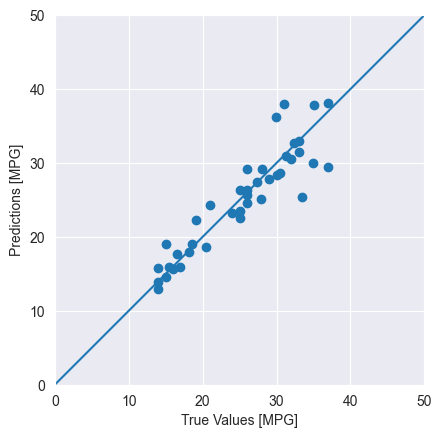

In [24]:
a = plt.axes(aspect='equal')
plt.scatter(y_test, y_predicted)
plt.xlabel('True Values [MPG]')
plt.ylabel('Predictions [MPG]')
lims = [0, 50]
plt.xlim(lims)
plt.ylim(lims)
plt.plot(lims, lims)

## 🧠 What This Tells You
- The model is learning meaningful relationships in the data.
- It’s not perfect, but it’s not random or broken either.
- You could quantify this further using metrics like R² score, MAE, or RMSE.


We plot the error distribution.

Text(0, 0.5, 'Count')

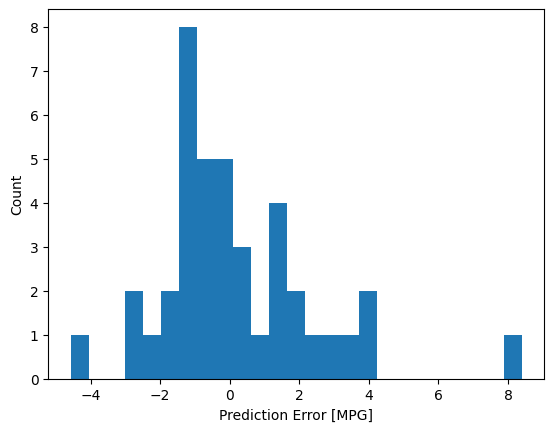

In [25]:
error = y_predicted - y_test
plt.hist(error, bins=25)
plt.xlabel('Prediction Error [MPG]')
plt.ylabel('Count')

## 📊 What Your Histogram Reveals
You're plotting the residuals (i.e., error = y_predicted - y_test), which show how far off each prediction is from the true value. Here's what to look for:
### ✅ If the model is performing well:
- The histogram should be centered around 0 → predictions are unbiased.
- It should be roughly symmetric → errors are evenly distributed.
- Most errors should be small in magnitude → tight clustering near zero.
### ⚠️ If the model is struggling:
- The histogram may be skewed → consistent over- or under-prediction.
- It may have long tails → large errors for some samples.
- It may be multi-modal → suggesting the model behaves differently across subgroups.

## 🧠 What Your Plot Suggests (based on the image)
- The error distribution is centered slightly left of zero, suggesting a slight underprediction bias.
- Most errors fall between −4 and +8 MPG, which is a moderate spread.
- The peak around −2 MPG indicates that many predictions are a bit lower than the true values.


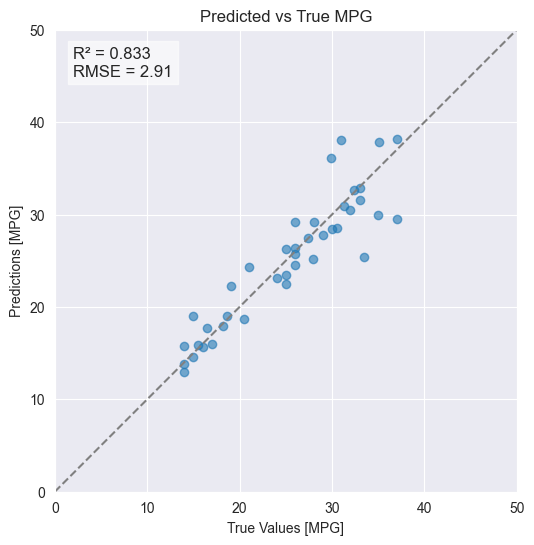

In [25]:
### me
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

# Compute metrics
r2 = r2_score(y_test, y_predicted)
rmse = np.sqrt(mean_squared_error(y_test, y_predicted))

# Create scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_predicted, alpha=0.6)
plt.plot([0, 50], [0, 50], color='gray', linestyle='--')  # reference line
plt.xlabel('True Values [MPG]')
plt.ylabel('Predictions [MPG]')
plt.title('Predicted vs True MPG')

# Annotate metrics
plt.text(2, 45, f'R² = {r2:.3f}\nRMSE = {rmse:.2f}', fontsize=12, bbox=dict(facecolor='white', alpha=0.6))

plt.grid(True)
plt.xlim([0, 50])
plt.ylim([0, 50])
plt.gca().set_aspect('equal', adjustable='box')
plt.show()